In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

board_freqs = [11.0, 13.0, 15.0, 17.0]  # Flickering board frequencies in Hz
dummy_freq = 10.0  # eyes closed: no key. Scored with the same SNR and FBCCA as the boards.
target_freqs = sorted(board_freqs + [dummy_freq])
# Hann main lobe is ±2 bins, so noise bins start at this offset. snr_n bins are used on each side.
snr_guard = 2
snr_n = 3
sr = 200
# Resting file from the same person and the same cap. None leaves the recording unchanged.
calibration_file = None #'0Hz2.csv'
data = pd.read_csv('QR17Hz_Final.csv')
# Band edges follow the flickering boards. 10 Hz and its 20 Hz harmonic sit inside this band.
bp_low = int(min(board_freqs) - 2)  # Lowest flickering board frequency minus 2
bp_high = int(max(board_freqs) * 2 + 2)  # 2nd harmonic of the highest flickering board frequency plus 3
eeg_c
els = ['Channel_1', 'Channel_2', 'Channel_3', 'Channel_4']
eeg_data = data[eeg_channels].values  # Shape: (n_samples, 4)
timestamps = np.arange(len(eeg_data)) / sr  # Assuming timestamps are sequential integers

# SNR is taken at each candidate and at its second harmonic. The closest of those
# lines sets the shortest window whose noise bins stay off the neighboring line.
scored_freqs = np.array(sorted({f * h for f in target_freqs for h in (1, 2)}))
scored_gaps = np.diff(scored_freqs)
closest_gap_idx = int(np.argmin(scored_gaps))
min_scored_gap_hz = float(scored_gaps[closest_gap_idx])
# Farthest noise bin is (guard + n - 1) bins away. Keep one bin between it and the next line.
min_window_sec = (snr_guard + snr_n) / min_scored_gap_hz
print(
    f"Closest scored lines: {scored_freqs[closest_gap_idx]:g} Hz and "
    f"{scored_freqs[closest_gap_idx + 1]:g} Hz ({min_scored_gap_hz:g} Hz apart)"
)
print(f"Minimum window: {min_window_sec:.2f} s")

Closest scored lines: 10 Hz and 11 Hz (1 Hz apart)
Minimum window: 5.00 s


In [43]:
from scipy.signal import butter, filtfilt, iirnotch

def bandpass_filter(data, lowcut, highcut, fs):
    nyquist = fs / 2
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(6, [low, high], btype='band')
    return filtfilt(b, a, data, axis=0)

def notch_filter(data, freq, fs):
    nyquist = fs / 2
    b, a = iirnotch(freq / nyquist, 30)
    return filtfilt(b, a, data, axis=0)

eeg_filtered = bandpass_filter(eeg_data, bp_low, bp_high, sr)
eeg_filtered = notch_filter(eeg_filtered, 50, sr)
print(eeg_filtered.shape)

(6994, 4)


In [44]:
# Optional calibration. The resting file supplies two things that stay present
# during the task: the common spatial noise, and each channel's stationary spectrum.
# The common component is projected out, then each channel is spectrally whitened
# by its smoothed resting spectrum. A flicker line that was absent at rest remains.
if calibration_file:
    cal_raw = pd.read_csv(calibration_file)[eeg_channels].values
    cal = bandpass_filter(cal_raw, bp_low, bp_high, sr)
    cal = notch_filter(cal, 50, sr)

    cal_centered = cal - cal.mean(axis=0)
    cov = np.cov(cal_centered, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    common = eigenvectors[:, -1].copy()
    if np.sum(common) < 0.0:
        common = -common
    common = common / np.linalg.norm(common)
    common_fraction = float(eigenvalues[-1] / np.sum(eigenvalues))

    def remove_common(eeg, spatial):
        spatial = spatial / np.linalg.norm(spatial)
        return eeg - np.outer(eeg @ spatial, spatial)

    cal = remove_common(cal, common)
    eeg_filtered = remove_common(eeg_filtered, common)

    seg = int(5 * sr)
    seg -= seg % 2
    if seg < 64 or seg > cal.shape[0]:
        seg = cal.shape[0] - (cal.shape[0] % 2)
    step = max(1, seg // 2)
    taper = np.hanning(seg)
    rest_freqs = np.fft.rfftfreq(seg, 1.0 / sr)
    rest_psd = np.zeros((len(eeg_channels), len(rest_freqs)))
    n_seg = 0
    for start in range(0, cal.shape[0] - seg + 1, step):
        chunk = cal[start:start + seg]
        for ch in range(len(eeg_channels)):
            centered = chunk[:, ch] - np.mean(chunk[:, ch])
            rest_psd[ch] += np.abs(np.fft.rfft(centered * taper)) ** 2
        n_seg += 1
    rest_psd /= max(n_seg, 1)

    df = rest_freqs[1] - rest_freqs[0]
    sigma = 0.5 / df
    radius = max(1, int(round(3 * sigma)))
    k = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (k / sigma) ** 2)
    kernel /= kernel.sum()
    rest_psd = np.vstack([np.convolve(row, kernel, mode='same') for row in rest_psd])

    # Dividing one FFT of the whole recording by the resting spectrum is a
    # circular convolution. Gain outside the passband is enormous because the
    # resting power there is ~0, so the EEG shrinks by ~1/sqrt(power) and the
    # two ends become impulses. Those impulses are a flat line on the FFT plot.
    # Use the same gain as a zero-phase FIR instead: median in-band gain is 1,
    # peaks are cut by at most 8x, valleys are boosted by at most 4x, and the
    # gain fades to 1 within 1 Hz outside the passband.
    from scipy.signal import firwin2

    def resting_gain(psd):
        eps = 0.05 * np.median(psd[rest_freqs >= 1.0])
        gain = 1.0 / np.sqrt(psd + eps)
        band = (rest_freqs >= bp_low) & (rest_freqs <= bp_high)
        gain = np.clip(gain / np.median(gain[band]), 0.125, 4.0)
        fade = np.ones_like(rest_freqs)
        width = 1.0
        below = rest_freqs < bp_low
        above = rest_freqs > bp_high
        fade[below] = np.clip((rest_freqs[below] - (bp_low - width)) / width, 0.0, 1.0)
        fade[above] = np.clip(((bp_high + width) - rest_freqs[above]) / width, 0.0, 1.0)
        fade = 0.5 - 0.5 * np.cos(np.pi * fade)
        return (1.0 - fade) + gain * fade

    freqs_norm = rest_freqs / (sr / 2.0)
    n_taps = 401
    if eeg_filtered.shape[0] < 3 * n_taps:
        n_taps = max(31, (eeg_filtered.shape[0] // 3) // 2 * 2 + 1)
    whitened = np.empty_like(eeg_filtered)
    for ch in range(len(eeg_channels)):
        gain = resting_gain(rest_psd[ch])
        taps = firwin2(n_taps, freqs_norm, np.sqrt(np.maximum(gain, 1e-3)))
        whitened[:, ch] = filtfilt(taps, [1.0], eeg_filtered[:, ch])
    eeg_filtered = whitened

    print(f'Calibrated with {calibration_file}')
    print(f'Common-mode variance: {100 * common_fraction:.1f}%')
    print('Common-mode weights:', np.round(common, 3))
else:
    print('No calibration file. Recording used as filtered.')
print(eeg_filtered.shape)


No calibration file. Recording used as filtered.
(6994, 4)


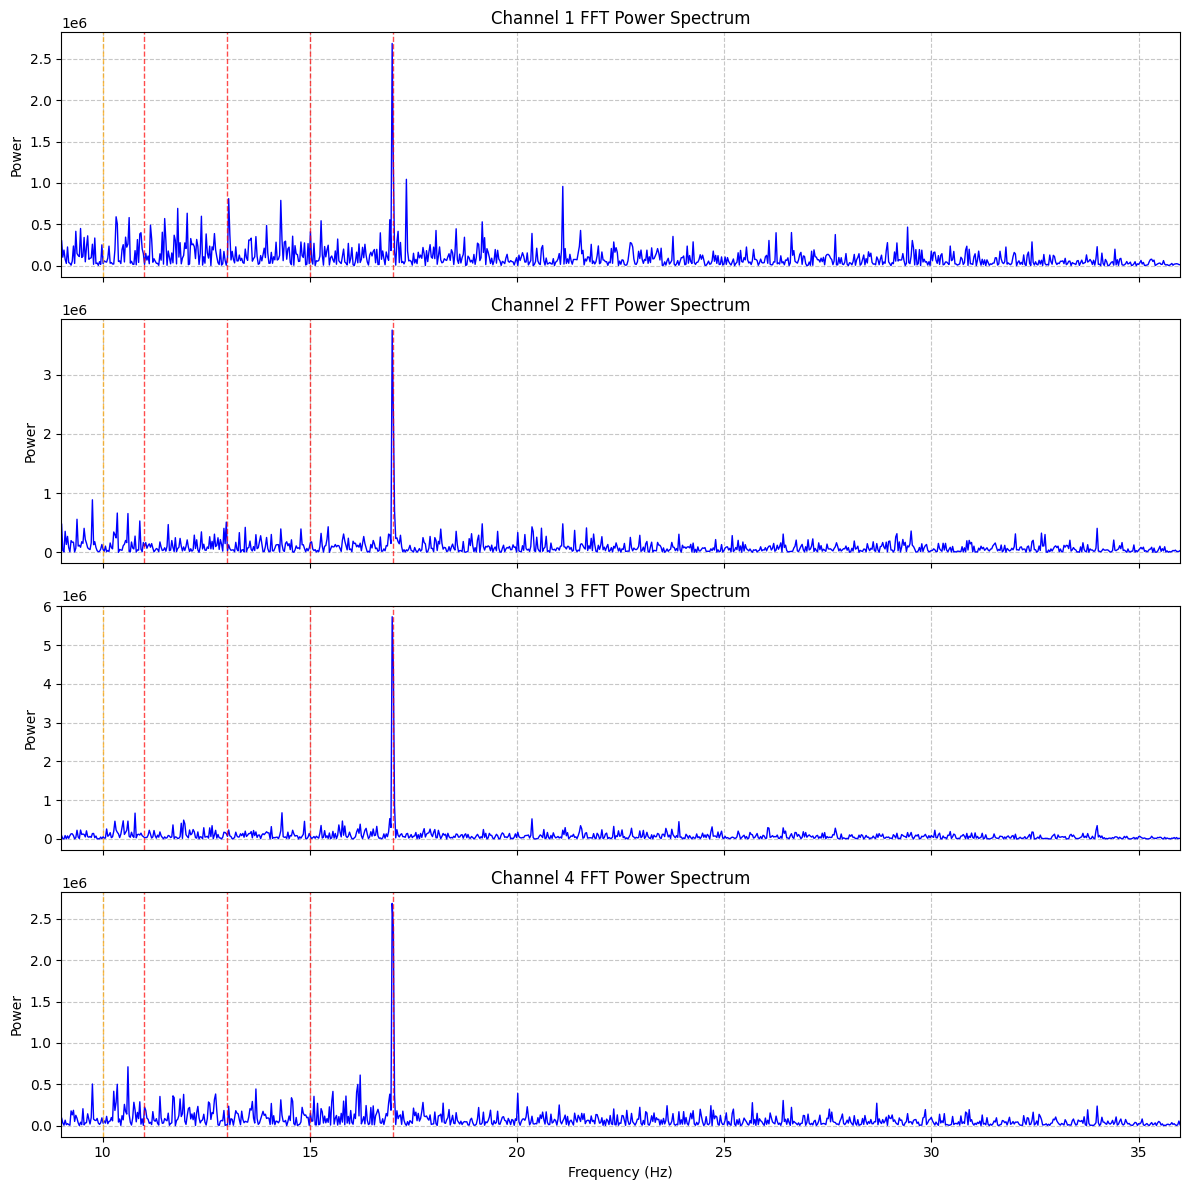

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# 1. Define signal parameters
sr = 200  # Sampling rate in Hz
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]

# 2. Generate the frequency axis
# fftfreq returns both positive and negative frequencies
freqs = fftfreq(n_samples, 1/sr)

# We only need the positive half of the spectrum for plotting
pos_freqs = freqs[:n_samples//2]

fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)

# 4. Rectangular-window FFT of the whole record.
for ch in range(n_channels):
    channel_data = eeg_filtered[:, ch]
    channel_data = channel_data - np.mean(channel_data)

    fft_values = fft(channel_data)
    # One-sided power. Raw |FFT|² has units µV²·samples²; dividing by N²
    # and doubling the positive bins reports each line in µV².
    power_spectrum = np.abs(fft_values[:n_samples//2]) ** 2
    power_spectrum[1:] *= 2.0 / (n_samples ** 2)

    # Plot from index 1 onward to explicitly drop the 0 Hz spike
    axes[ch].plot(pos_freqs[1:], power_spectrum[1:], color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} FFT Power Spectrum')
    axes[ch].set_ylabel(r'Power ($\mu V^2$)')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(bp_low, bp_high)
    for f in target_freqs:
        axes[ch].axvline(
            f, color='orange' if f == dummy_freq else 'r',
            linestyle='--', alpha=0.7, linewidth=1)

# 5. Formatting
axes[-1].set_xlabel('Frequency (Hz)')

# Zoom in on the frequency band relevant to SSVEP (e.g., 0 to 50 Hz)
plt.tight_layout()
plt.show()

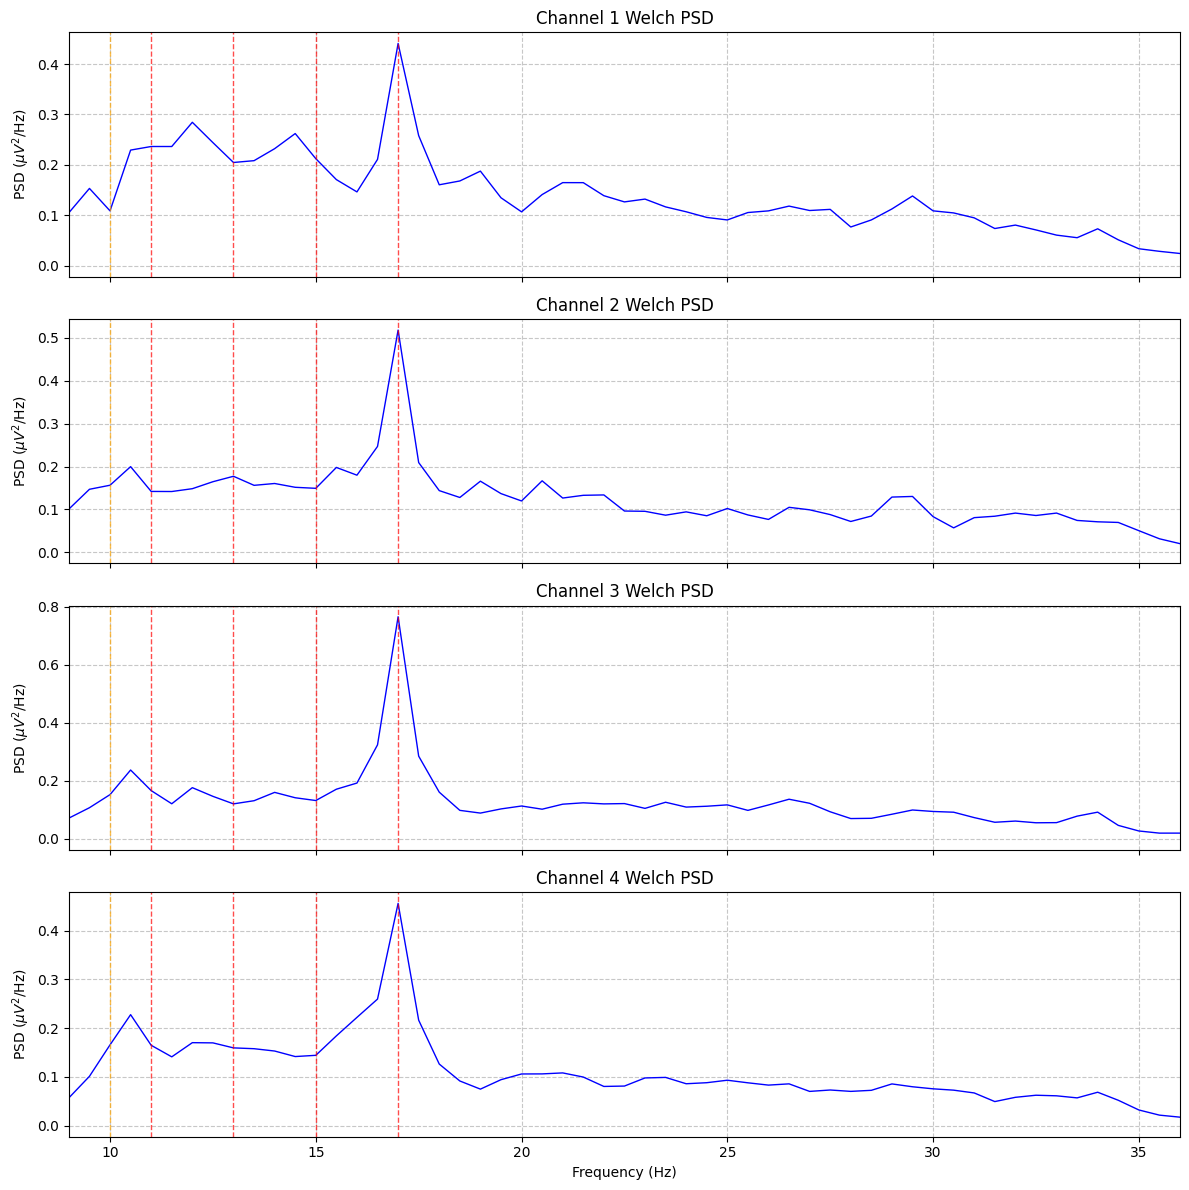

In [46]:
from scipy.signal import welch

# Welch PSD of the same filtered recording. scaling='density' makes the
# one-sided spectrum a density: the values are µV^2/Hz, and integrating
# over frequency recovers the variance of the windowed signal.
# A 2 s Hann segment (0.5 Hz resolution, 50% overlap) is what turns the
# rectangular-FFT spike comb into the background envelope.
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]
nperseg = min(2 * sr, n_samples)

fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)
for ch in range(n_channels):
    freqs_w, psd = welch(
        eeg_filtered[:, ch],
        fs=sr,
        window='hann',
        nperseg=nperseg,
        noverlap=nperseg // 2,
        detrend='constant',
        scaling='density',
    )
    axes[ch].plot(freqs_w, psd, color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} Welch PSD')
    axes[ch].set_ylabel(r'PSD ($\mu V^2$/Hz)')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(bp_low, bp_high)
    for f in target_freqs:
        axes[ch].axvline(
            f, color='orange' if f == dummy_freq else 'r',
            linestyle='--', alpha=0.7, linewidth=1)

axes[-1].set_xlabel('Frequency (Hz)')
plt.tight_layout()
plt.show()


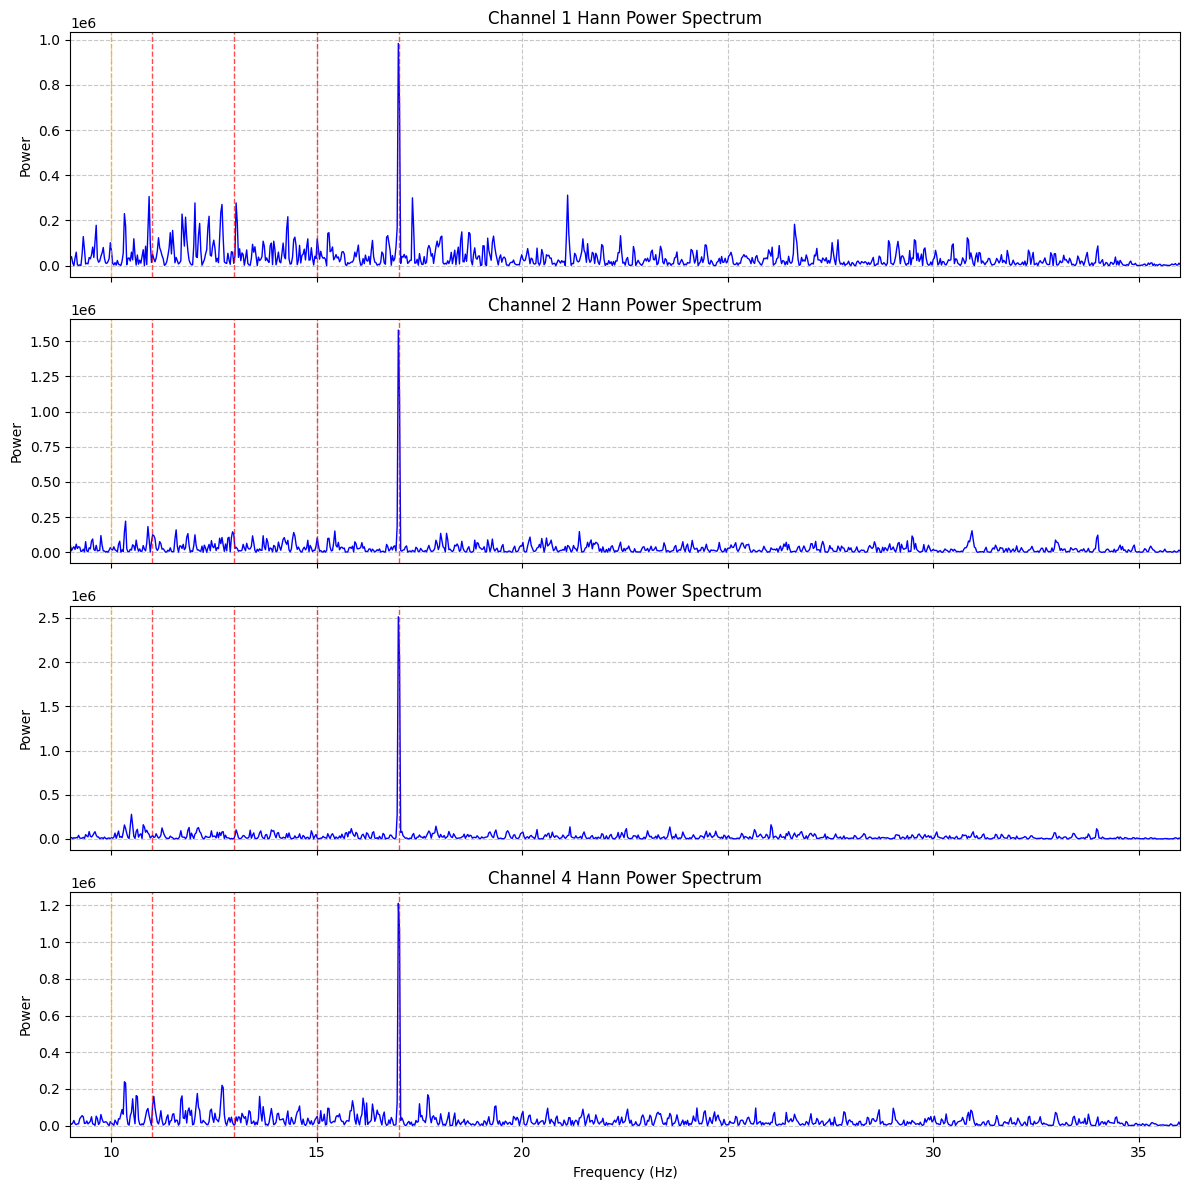

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# Hann-windowed power spectrum of the whole record. Same binning the SNR uses.
# The axis is scaled to µV²; SNR itself is a ratio and is unchanged by that scale.
sr = 200
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]
taper = np.hanning(n_samples)
hann_scale = np.sum(taper)

# 3. Set up the plotting grid (4 rows, 1 column)
fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)

# 4. Hann-windowed power spectrum of the whole record. Same spectrum the SNR uses.
for ch in range(n_channels):
    channel_data = eeg_filtered[:, ch]
    channel_data = (channel_data - np.mean(channel_data)) * taper

    fft_values = fft(channel_data)
    pos_freqs = fftfreq(n_samples, 1 / sr)[:n_samples // 2]
    power_spectrum = np.abs(fft_values[:n_samples // 2]) ** 2
    # Divide by the squared sum of the Hann window so a tone is reported in µV².
    power_spectrum[1:] *= 2.0 / (hann_scale ** 2)

    non_zero_idx = pos_freqs > 0
    axes[ch].plot(pos_freqs[non_zero_idx], power_spectrum[non_zero_idx], color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} Hann Power Spectrum')
    axes[ch].set_ylabel(r'Power ($\mu V^2$)')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(bp_low, bp_high)
    for f in target_freqs:
        axes[ch].axvline(
            f, color='orange' if f == dummy_freq else 'r',
            linestyle='--', alpha=0.7, linewidth=1)

# 5. Formatting
axes[-1].set_xlabel('Frequency (Hz)')

plt.tight_layout()
plt.show()


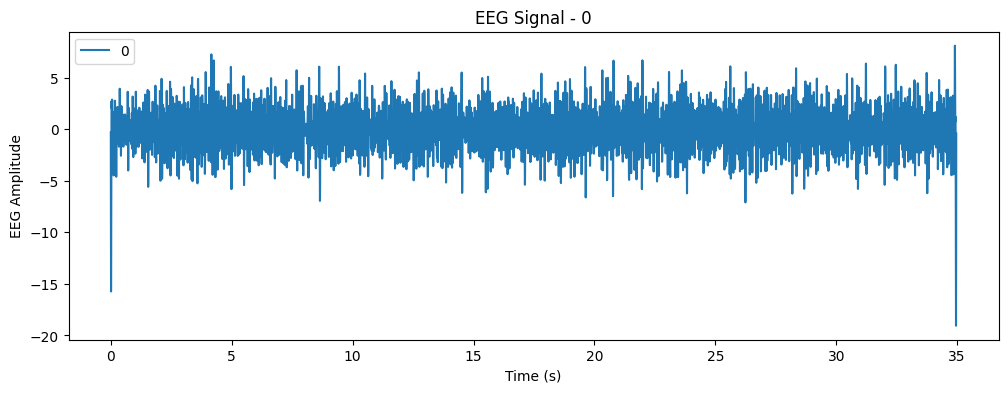

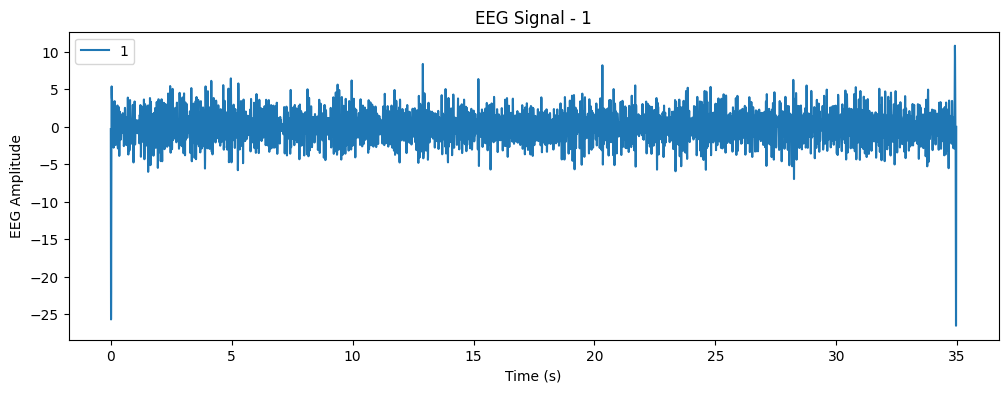

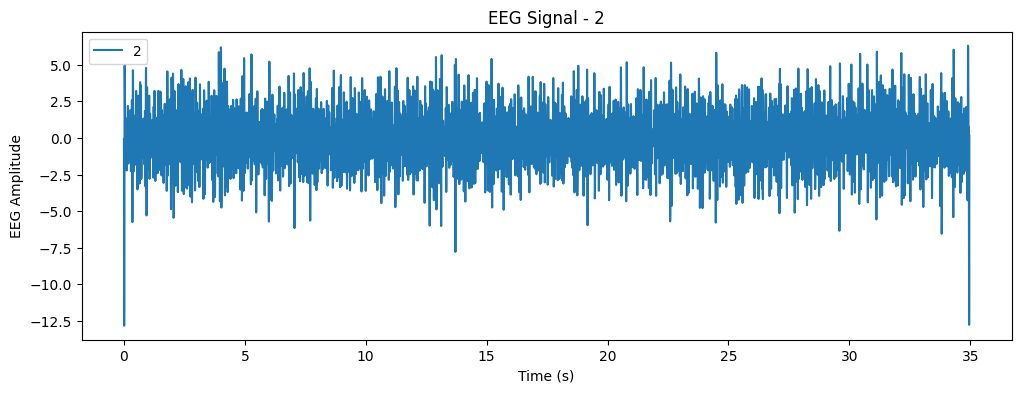

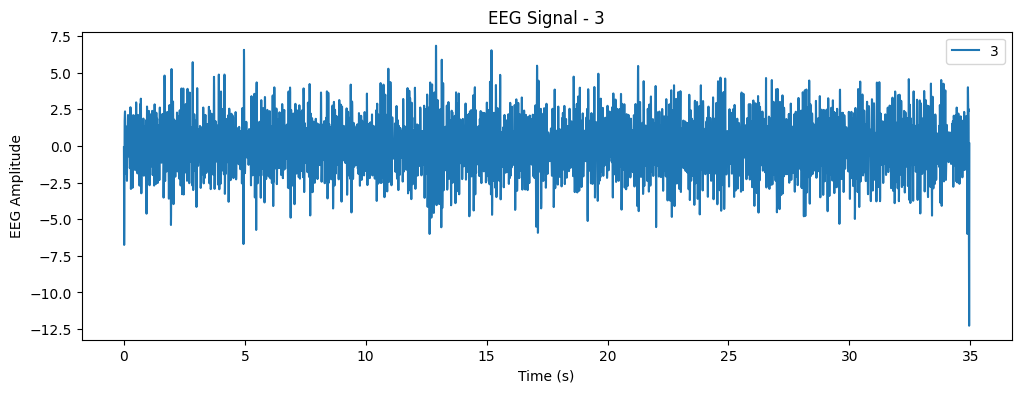

In [48]:
for channel in range(4):
    plt.figure(figsize=(12, 4))
    plt.plot(timestamps, eeg_filtered[:, channel], label=channel)
    plt.xlabel('Time (s)')
    plt.ylabel('EEG Amplitude')
    plt.title(f'EEG Signal - {channel}')
    plt.legend()
    plt.show()


In [49]:
windows = []
window_size = 5 * sr  # seconds * 200 Hz
step_size = 5 * sr     # seconds * 200 Hz
window_sec = window_size / sr
if window_sec + 1e-9 < min_window_sec:
    print(
        f"Window is {window_sec:.2f} s. Noise bins overlap the next scored line "
        f"below {min_window_sec:.2f} s."
    )

# Added +1 to ensure the final window is captured if it fits perfectly
for start in range(0, len(eeg_filtered) - window_size + 1, step_size):
    end = start + window_size
    window = eeg_filtered[start:end, :]
    windows.append(window)

print(f"Created {len(windows)} windows")
print(f"Each window shape: {windows[0].shape}")

Created 6 windows
Each window shape: (1000, 4)


In [50]:
def SNR(power_spectrum, freqs, target_freq, n=3, guard=2):
    """Peak SNR at target_freq.

    Noise bins start `guard` bins off the candidate so the Hann main lobe is not
    counted as noise. A line fit through those bins is the local baseline.
    A shoulder, where the candidate is not above that line, scores 0.
    Otherwise SNR = power(f) / max(mean(left), mean(right)).
    """
    idx = int(np.argmin(np.abs(freqs - target_freq)))
    far = guard + n - 1
    left_lo = idx - far
    left_hi = idx - guard + 1
    right_lo = idx + guard
    right_hi = idx + far + 1
    if left_lo < 0 or right_hi > len(power_spectrum):
        return 0.0

    left = power_spectrum[left_lo:left_hi]
    right = power_spectrum[right_lo:right_hi]
    if left.size < n or right.size < n:
        return 0.0

    signal = float(power_spectrum[idx])
    x = np.concatenate([freqs[left_lo:left_hi], freqs[right_lo:right_hi]])
    y = np.concatenate([left, right])
    slope, intercept = np.polyfit(x, y, 1)
    excess = signal - (slope * float(freqs[idx]) + intercept)
    if excess <= 0.0:
        return 0.0

    noise = max(float(np.mean(left)), float(np.mean(right)))
    if noise <= 0.0:
        return 0.0
    return signal / noise

Window 1 | Max Freq: 17 Hz | Gate Ratio: 16.62


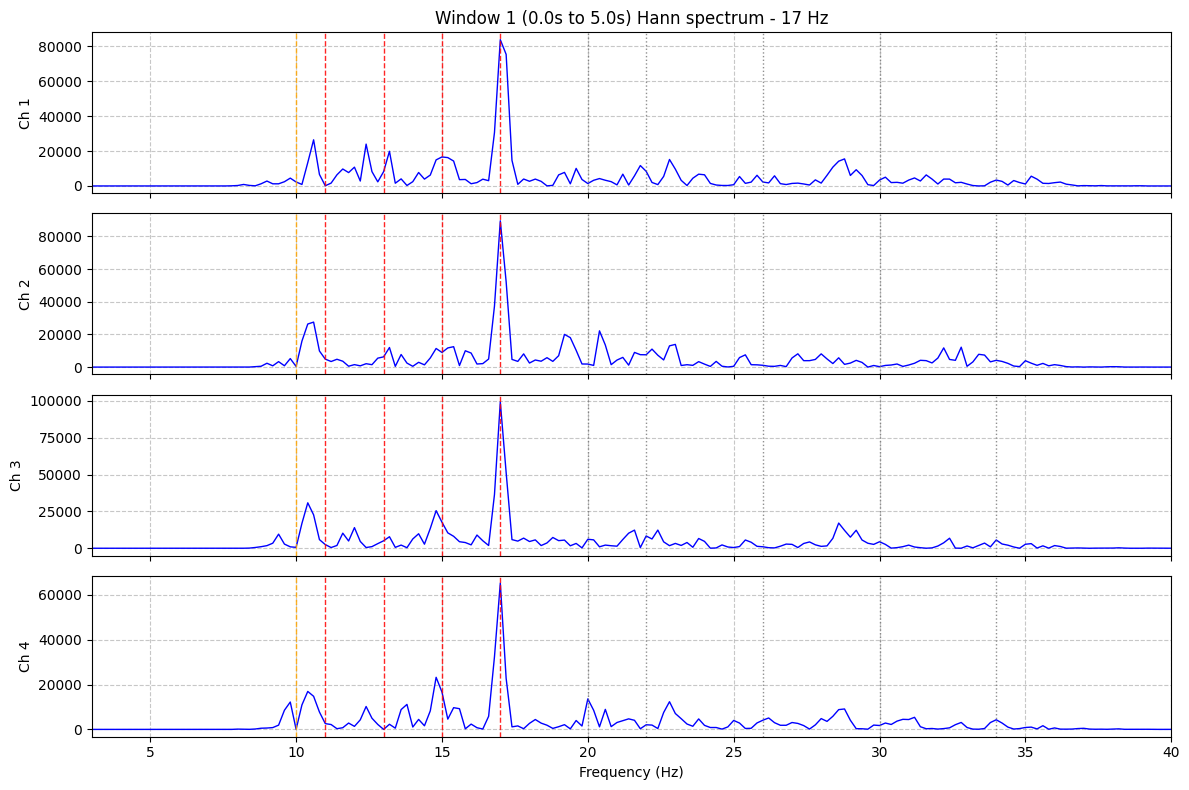

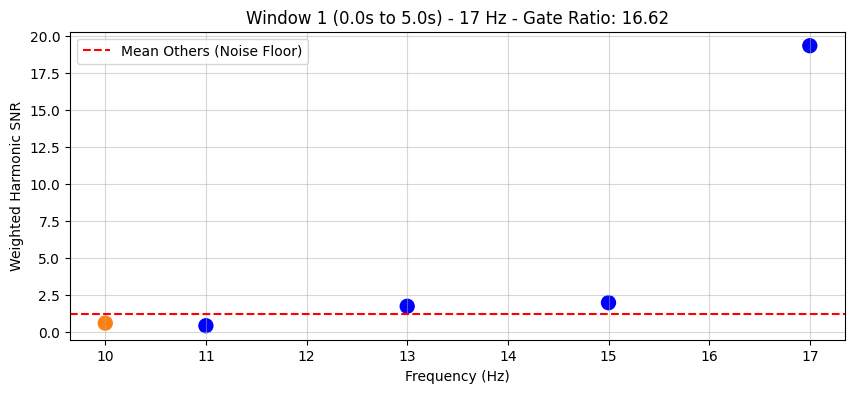

Window 2 | Max Freq: 17 Hz | Gate Ratio: 4.89


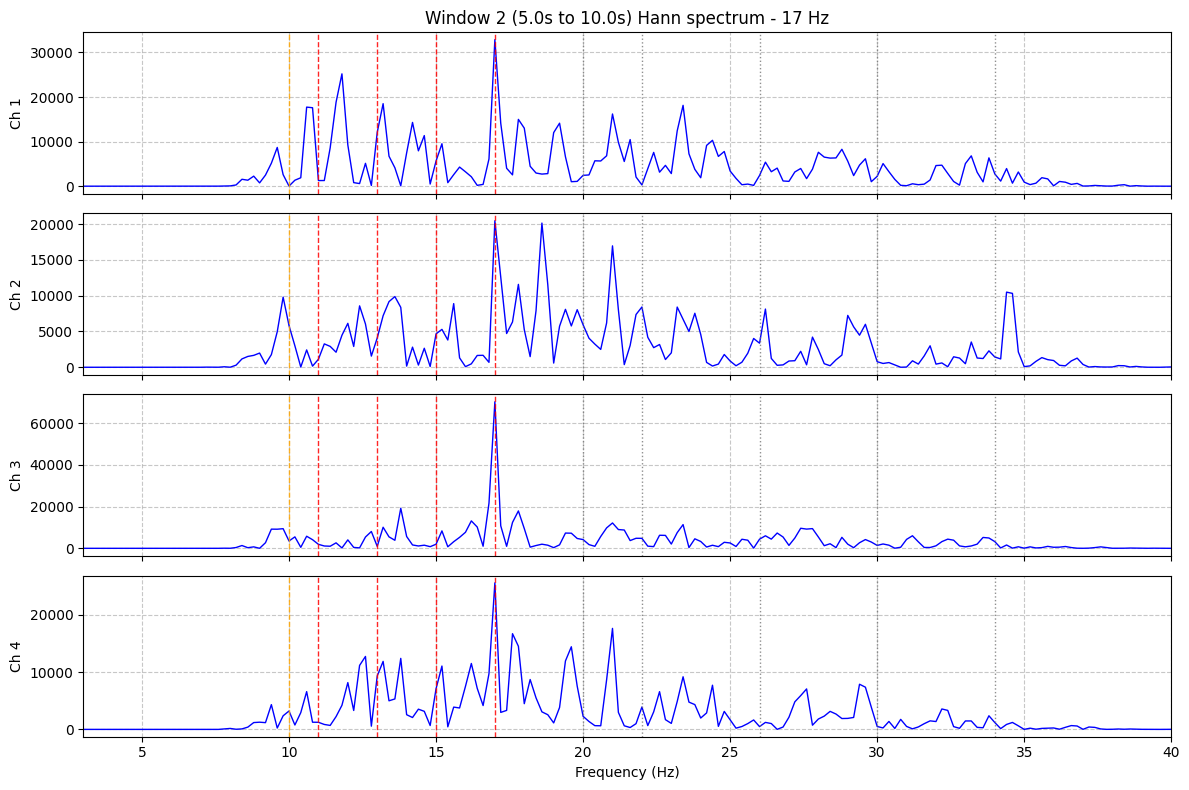

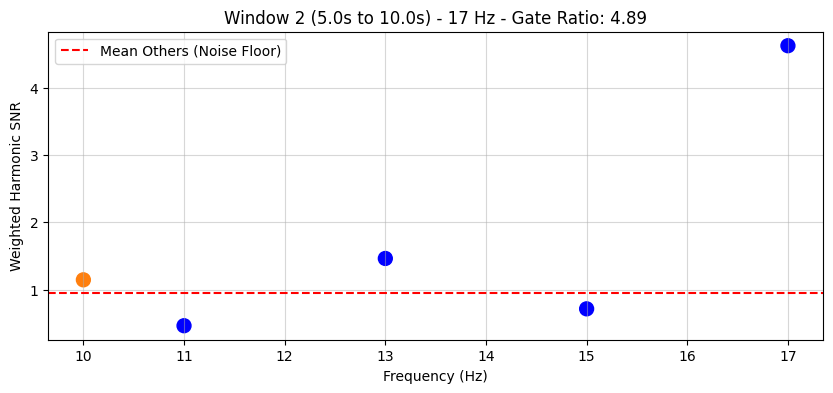

Window 3 | Max Freq: 17 Hz | Gate Ratio: 4.80


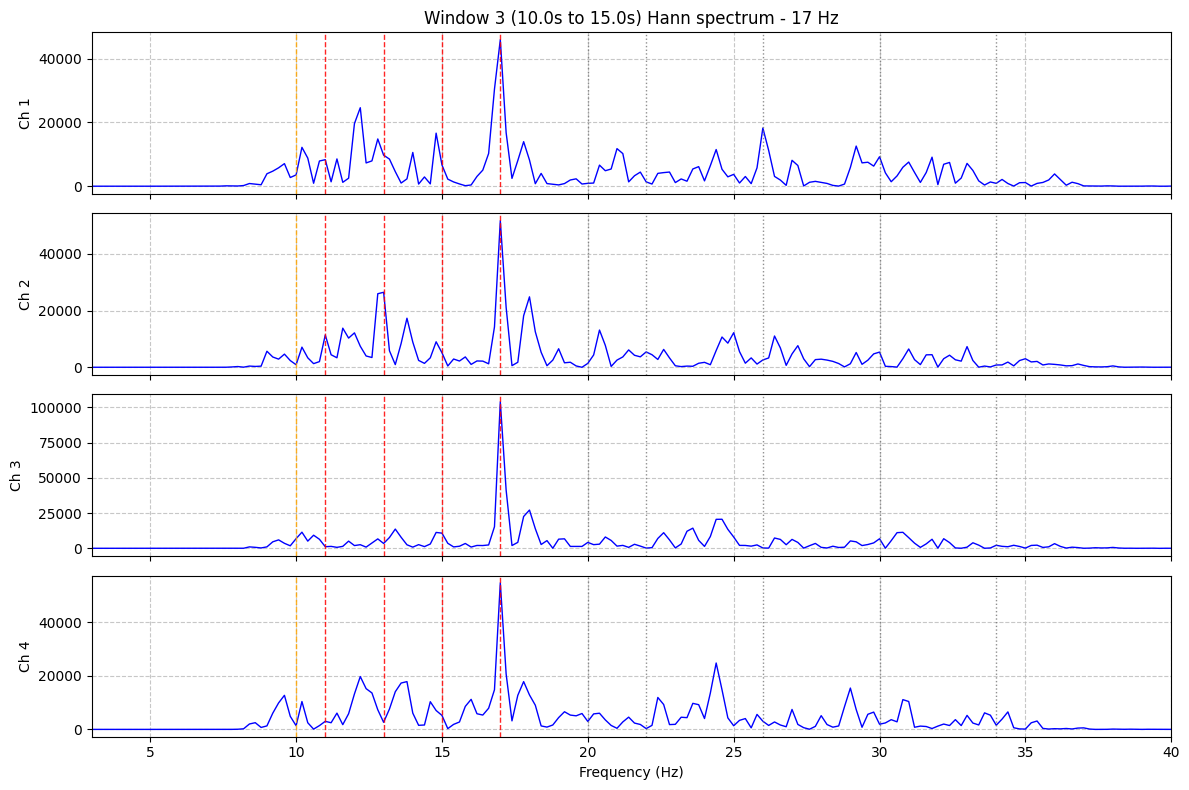

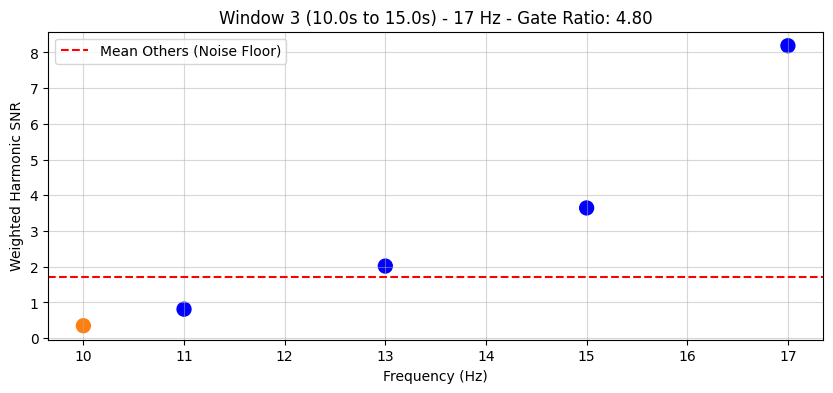

Window 4 | Max Freq: 17 Hz | Gate Ratio: 14.13


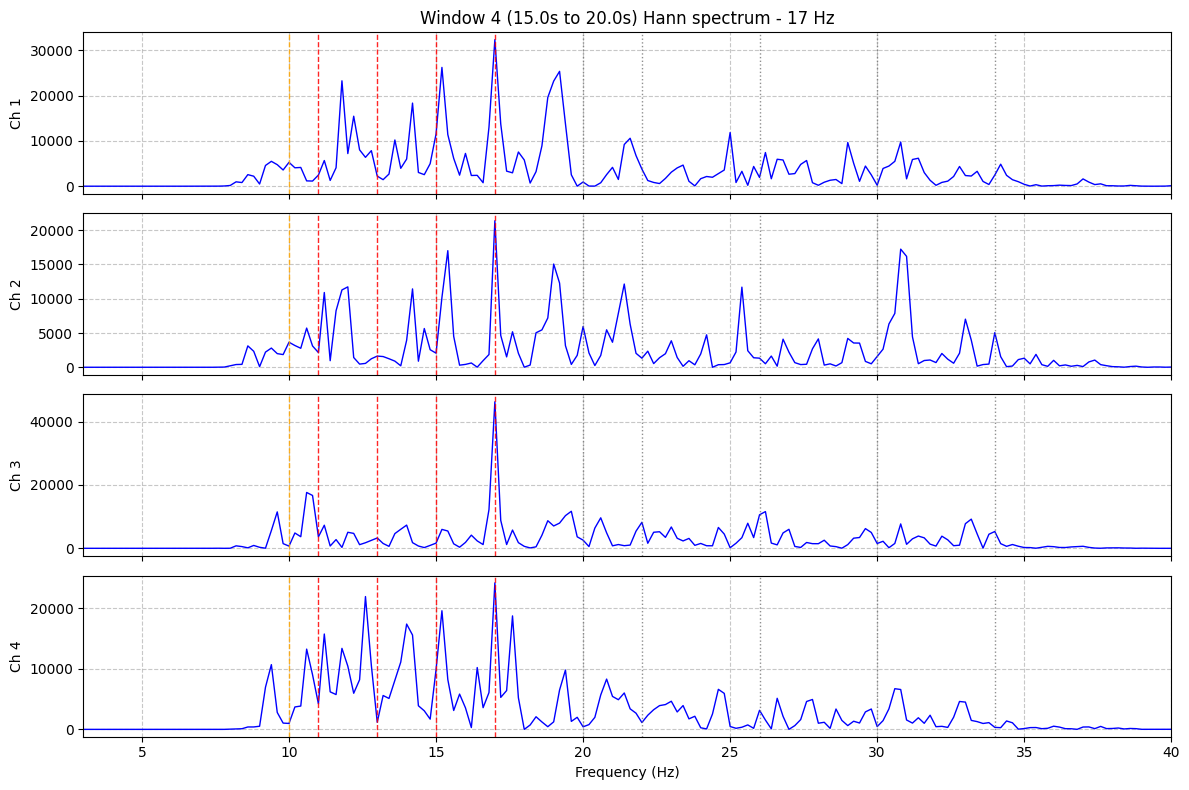

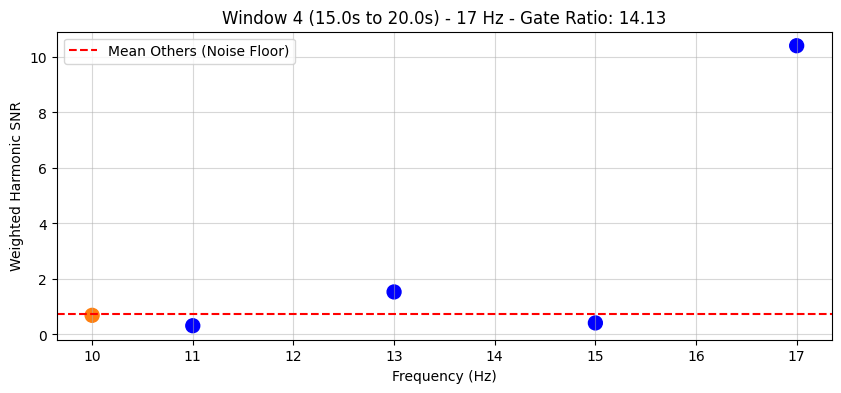

Window 5 | Max Freq: 17 Hz | Gate Ratio: 8.65


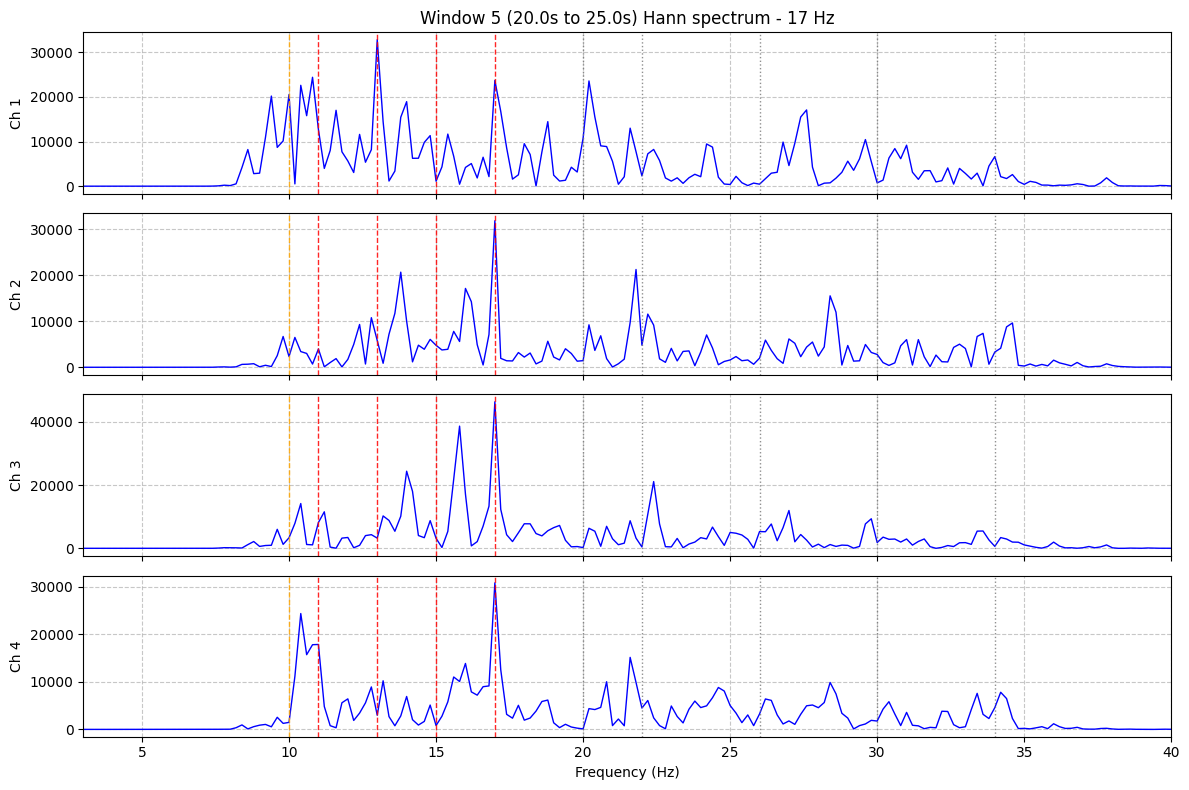

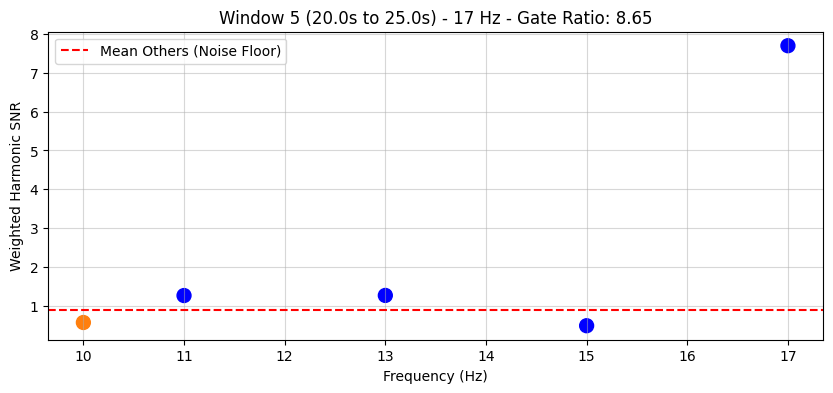

Window 6 | Max Freq: 17 Hz | Gate Ratio: 3.36


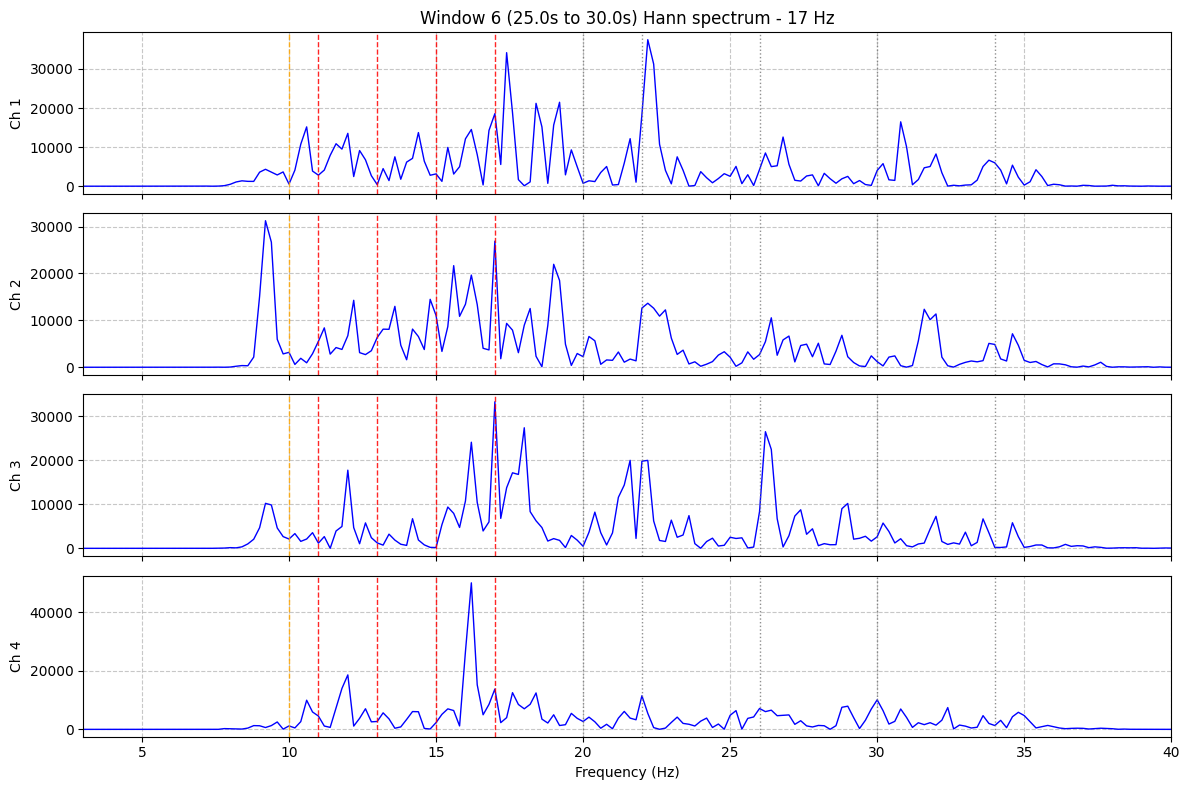

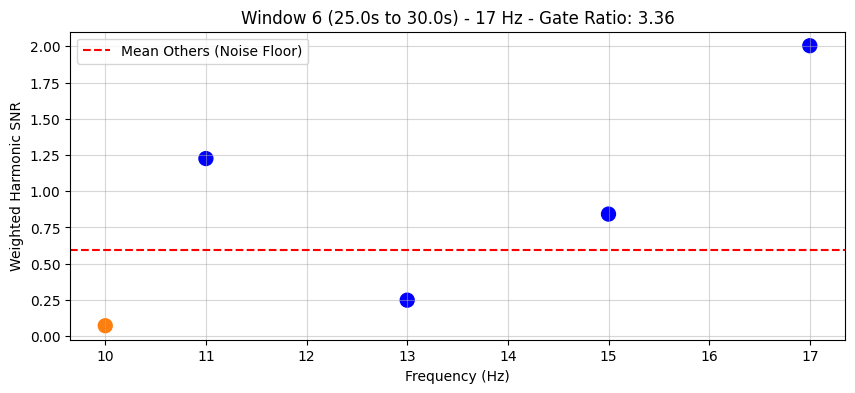

In [51]:
from scipy.fft import fft, fftfreq
import numpy as np
import matplotlib.pyplot as plt

# Assuming 'windows' and 'sr' are defined earlier
n_samples = windows[0].shape[0]
n_channels = windows[0].shape[1]

# 1. Define Fixed Channel Weights (e.g., O1, O2 get 70% of the weight, PO7, PO8 get 30%)
# Adjust the index positions to match your actual data array order
channel_weights = np.array([0.15, 0.35, 0.35, 0.15])

gate_ratios = []

# Process and plot each window separately
for i, window in enumerate(windows):
    # window_powers will store a list of 4 channel scores for each frequency
    window_powers = {freq: [] for freq in target_freqs}
    n_samples = window.shape[0]
    taper = np.hanning(n_samples)
    spectra = []
    positive_freqs = None

    for ch in range(n_channels):
        channel_data = window[:, ch]
        channel_data = (channel_data - np.mean(channel_data)) * taper

        fft_values = fft(channel_data)
        fft_freqs = fftfreq(n_samples, 1/sr)

        power_spectrum = np.abs(fft_values[:n_samples//2]) ** 2
        positive_freqs = fft_freqs[:n_samples//2]
        spectra.append(power_spectrum)

        for target_freq in target_freqs:
            snr_1 = SNR(power_spectrum, positive_freqs, target_freq, n=snr_n, guard=snr_guard)
            snr_2 = SNR(power_spectrum, positive_freqs, target_freq * 2.0, n=snr_n, guard=snr_guard)

            # Harmonic Summation
            H_snr = snr_1 + 0.5 * snr_2
            window_powers[target_freq].append(H_snr)

    # 2. Weighted Average across channels for this window
    weighted_avg_powers = [np.average(window_powers[freq], weights=channel_weights) for freq in target_freqs]
    
    # 3. Calculate the Gate Ratio
    max_score = np.max(weighted_avg_powers)
    max_idx = np.argmax(weighted_avg_powers)
    
    # Extract the scores of the non-target frequencies to find the noise floor
    other_scores = [score for j, score in enumerate(weighted_avg_powers) if j != max_idx]
    mean_other_scores = np.mean(other_scores)
    gate_ratio = 0.0 if mean_other_scores <= 0.0 else max_score / mean_other_scores
    gate_ratios.append(gate_ratio)

    winner = target_freqs[max_idx]
    winner_label = "no input" if winner == dummy_freq else f"{winner:g} Hz"
    start_time = (i * step_size) / sr if 'step_size' in locals() else 0
    end_time = start_time + (n_samples / sr)

    # Print the Gate Ratio for observation
    print(f"Window {i+1} | Max Freq: {winner_label} | Gate Ratio: {gate_ratio:.2f}")

    # Hann spectrum actually scored for this window. Red lines are boards, orange is the
    # dummy, dotted lines are the second harmonics.
    fig, axes = plt.subplots(n_channels, 1, figsize=(12, 8), sharex=True)
    if n_channels == 1:
        axes = [axes]
    nonzero = positive_freqs > 0
    for ch in range(n_channels):
        axes[ch].plot(positive_freqs[nonzero], spectra[ch][nonzero], color='b', linewidth=1)
        axes[ch].set_ylabel(f'Ch {ch + 1}')
        axes[ch].set_xlim(3, 40)
        axes[ch].grid(True, linestyle='--', alpha=0.7)
        for f in target_freqs:
            axes[ch].axvline(
                f, color='orange' if f == dummy_freq else 'r',
                linestyle='--', alpha=0.85, linewidth=1)
            axes[ch].axvline(2.0 * f, color='0.45', linestyle=':', alpha=0.8, linewidth=1)
    axes[0].set_title(
        f'Window {i+1} ({start_time:.1f}s to {end_time:.1f}s) Hann spectrum - {winner_label}'
    )
    axes[-1].set_xlabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 4))
    colors = ['tab:orange' if f == dummy_freq else 'b' for f in target_freqs]
    plt.scatter(target_freqs, weighted_avg_powers, marker='o', c=colors, s=100)
    plt.axhline(mean_other_scores, color='r', linestyle='--', label='Mean Others (Noise Floor)')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Weighted Harmonic SNR')
    plt.title(f'Window {i+1} ({start_time:.1f}s to {end_time:.1f}s) - {winner_label} - Gate Ratio: {gate_ratio:.2f}')
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.show()

# After the loop, you can analyze `gate_ratios` to find your resting state threshold
# e.g., threshold = np.mean(resting_gate_ratios) + 2.5 * np.std(resting_gate_ratios)

FBCCA sub-bands (Hz): [(9.0, 36.0), (20.0, 36.0)]
FBCCA weights: [1.25 0.67]
FBCCA window 1 | 17 Hz | scores=[0.072 0.048 0.05  0.141 0.243]
FBCCA window 2 | 17 Hz | scores=[0.021 0.063 0.034 0.047 0.295]
FBCCA window 3 | 17 Hz | scores=[0.038 0.086 0.135 0.052 0.285]
FBCCA window 4 | 17 Hz | scores=[0.058 0.057 0.128 0.041 0.275]
FBCCA window 5 | 17 Hz | scores=[0.068 0.044 0.116 0.086 0.221]
FBCCA window 6 | 17 Hz | scores=[0.035 0.098 0.102 0.057 0.179]


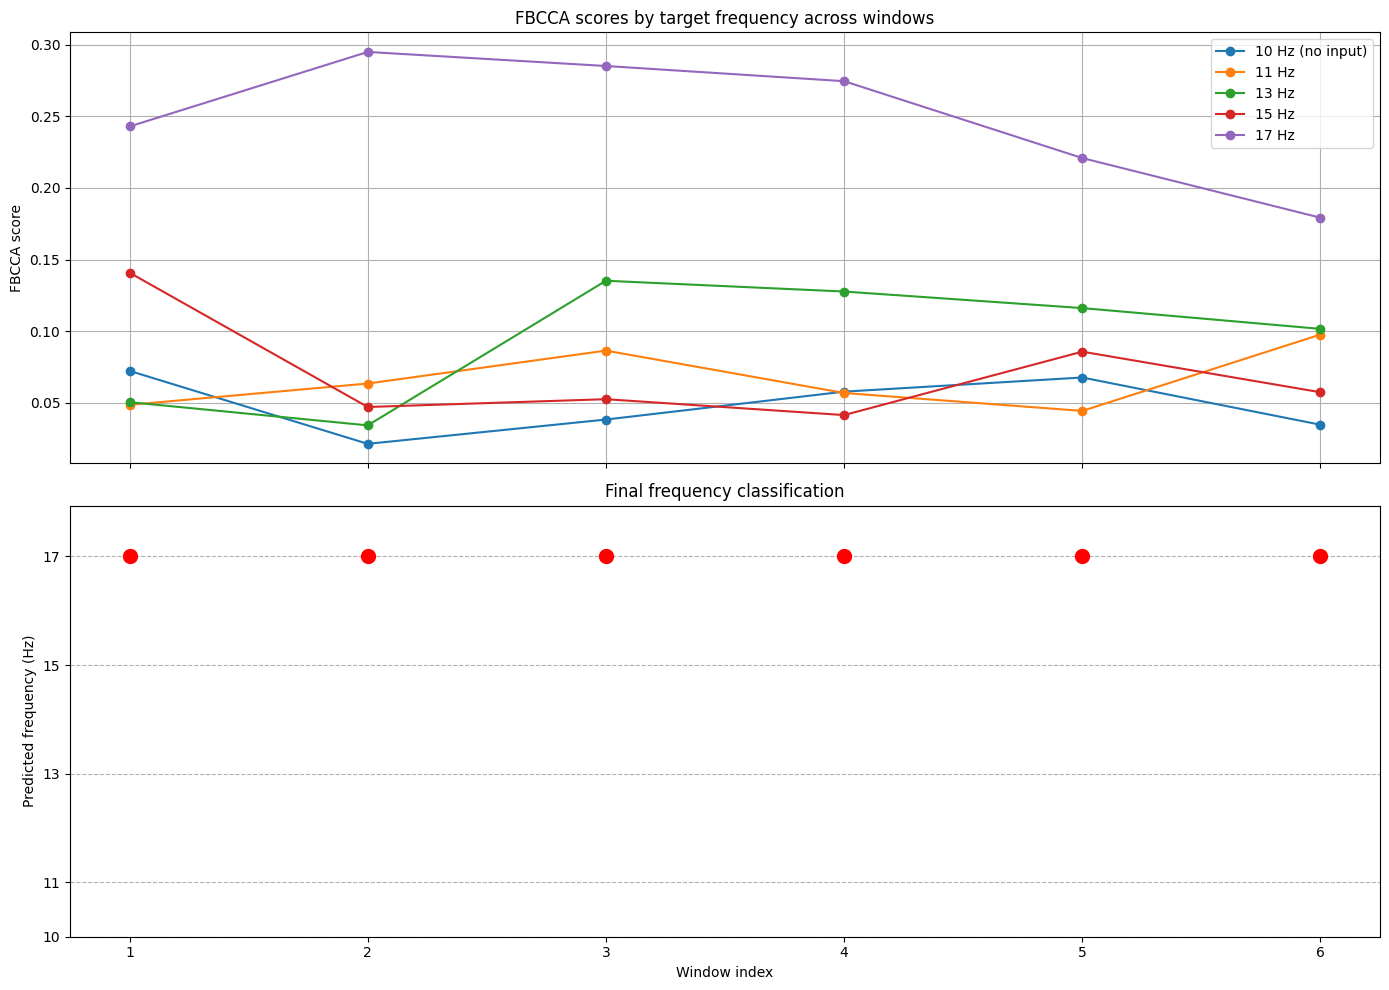

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

# Filter-bank CCA (Chen et al., J Neural Eng 2015), method M3.
# Each sub-band starts at harmonic n of the lowest flicker and runs up to the
# top of the recording band. Chen's bank ran to 88 Hz; this file is already
# limited to bp_high, and the Ganglion has nothing useful above that.
# The reference for every sub-band is still the sine/cosine pair at f, 2f, ...
# The score is the weighted sum of squared canonical correlations,
# w(n) = n^(-a) + b, with the M3 values a = 1.25 and b = 0.25.
# A third harmonic of 13, 15, or 17 Hz sits above bp_high, so the template
# uses two harmonics. The same channel penalty as before stays inside each
# CCA: filter-bank analysis does not stop PO7/PO8 from outvoting O1/O2.
n_harmonics = 2
fbcca_a = 1.25
fbcca_b = 0.25
sr = 200
n_samples = windows[0].shape[0]
t = np.arange(n_samples) / sr

f_base = float(min(board_freqs))
upper = float(bp_high)
subbands = []
for n in range(1, 9):
    low = max(float(bp_low), n * f_base - 2.0)
    if upper - low < 6.0:
        break
    subbands.append((low, upper))
fb_weights = np.array([n ** (-fbcca_a) + fbcca_b for n in range(1, len(subbands) + 1)])
subband_sos = [
    butter(4, [low / (sr / 2.0), upper / (sr / 2.0)], btype='band', output='sos')
    for low, _high in subbands
]
print('FBCCA sub-bands (Hz):', [(round(lo, 1), round(hi, 1)) for lo, hi in subbands])
print('FBCCA weights:', np.round(fb_weights, 3))

channel_weights = np.array([0.2, 0.3, 0.3, 0.2])
cca_penalty_strength = 0.2
channel_penalty = cca_penalty_strength * (channel_weights.max() / channel_weights - 1.0)

def generate_reference_signals(freqs, time_vector, harmonics):
    Y_refs = {}
    for f in freqs:
        y_f = []
        for h in range(1, harmonics + 1):
            y_f.append(np.sin(2 * np.pi * h * f * time_vector))
            y_f.append(np.cos(2 * np.pi * h * f * time_vector))
        Y_refs[f] = np.array(y_f).T
    return Y_refs

def penalized_cca(X, Y, penalty):
    X = np.asarray(X, dtype=float)
    Y = np.asarray(Y, dtype=float)
    X = X - X.mean(axis=0)
    Y = Y - Y.mean(axis=0)
    sx = X.std(axis=0)
    sy = Y.std(axis=0)
    sx[sx < 1e-12] = 1.0
    sy[sy < 1e-12] = 1.0
    X = X / sx
    Y = Y / sy
    n = X.shape[0]
    Cxx = (X.T @ X) / n + np.diag(penalty)
    Cyy = (Y.T @ Y) / n + 1e-6 * np.eye(Y.shape[1])
    Cxy = (X.T @ Y) / n
    M = np.linalg.solve(Cxx, Cxy) @ np.linalg.solve(Cyy, Cxy.T)
    ev = np.linalg.eigvals(M)
    return float(np.sqrt(np.clip(np.real(ev).max(), 0.0, 1.0)))

def fbcca_scores(window):
    scores = np.zeros(len(target_freqs))
    for weight, sos in zip(fb_weights, subband_sos):
        band = sosfiltfilt(sos, window, axis=0)
        for i, f in enumerate(target_freqs):
            rho = penalized_cca(band, Y_ref[f], channel_penalty)
            scores[i] += weight * rho * rho
    return scores

Y_ref = generate_reference_signals(target_freqs, t, n_harmonics)

predicted_freqs = []
cca_score_matrix = []

for window in windows:
    window_scores = fbcca_scores(window)
    cca_score_matrix.append(window_scores)
    best_freq_idx = int(np.argmax(window_scores))
    predicted_freqs.append(target_freqs[best_freq_idx])
    label = 'no input' if target_freqs[best_freq_idx] == dummy_freq else f'{target_freqs[best_freq_idx]:g} Hz'
    print(f'FBCCA window {len(predicted_freqs)} | {label} | scores={np.round(window_scores, 3)}')

cca_score_matrix = np.array(cca_score_matrix)
window_indices = np.arange(1, len(windows) + 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for i, f in enumerate(target_freqs):
    label = f'{f:g} Hz (no input)' if f == dummy_freq else f'{f:g} Hz'
    ax1.plot(window_indices, cca_score_matrix[:, i], marker='o', label=label)

ax1.set_ylabel('FBCCA score')
ax1.set_title('FBCCA scores by target frequency across windows')
ax1.legend()
ax1.grid(True)

ax2.scatter(window_indices, predicted_freqs, c='red', s=100, zorder=5)
ax2.set_yticks(target_freqs)
ax2.set_xlabel('Window index')
ax2.set_ylabel('Predicted frequency (Hz)')
ax2.set_title('Final frequency classification')
ax2.grid(True, axis='y', linestyle='--')

plt.tight_layout()
plt.show()


0Hz.csv                mountain top 10.49 Hz, envelope center 10.27 Hz, half-power  9.70-11.00 Hz
0Hz2.csv               mountain top 10.17 Hz, envelope center  9.96 Hz, half-power  9.26-10.86 Hz
0Hz3.csv               mountain top  9.74 Hz, envelope center  9.67 Hz, half-power  8.88-10.53 Hz
0Hz_L.csv              mountain top 10.03 Hz, envelope center 10.59 Hz, half-power  9.24-11.81 Hz
0Hz_S2.csv             mountain top 12.47 Hz, envelope center 12.43 Hz, half-power 11.89-13.19 Hz
0Hz_S3.csv             mountain top 11.73 Hz, envelope center 11.24 Hz, half-power 10.94-12.52 Hz
0Hz_S4.csv             mountain top 11.80 Hz, envelope center 10.78 Hz, half-power 10.85-13.08 Hz
0Hz_S5.csv             mountain top 11.09 Hz, envelope center 10.44 Hz, half-power 10.51-12.48 Hz
0Hz_T.csv              mountain top  9.35 Hz, envelope center  9.44 Hz, half-power  8.58-10.12 Hz
0Hz_T2.csv             mountain top  9.33 Hz, envelope center  9.38 Hz, half-power  8.69- 9.99 Hz
0hz_eyeclosed.csv   

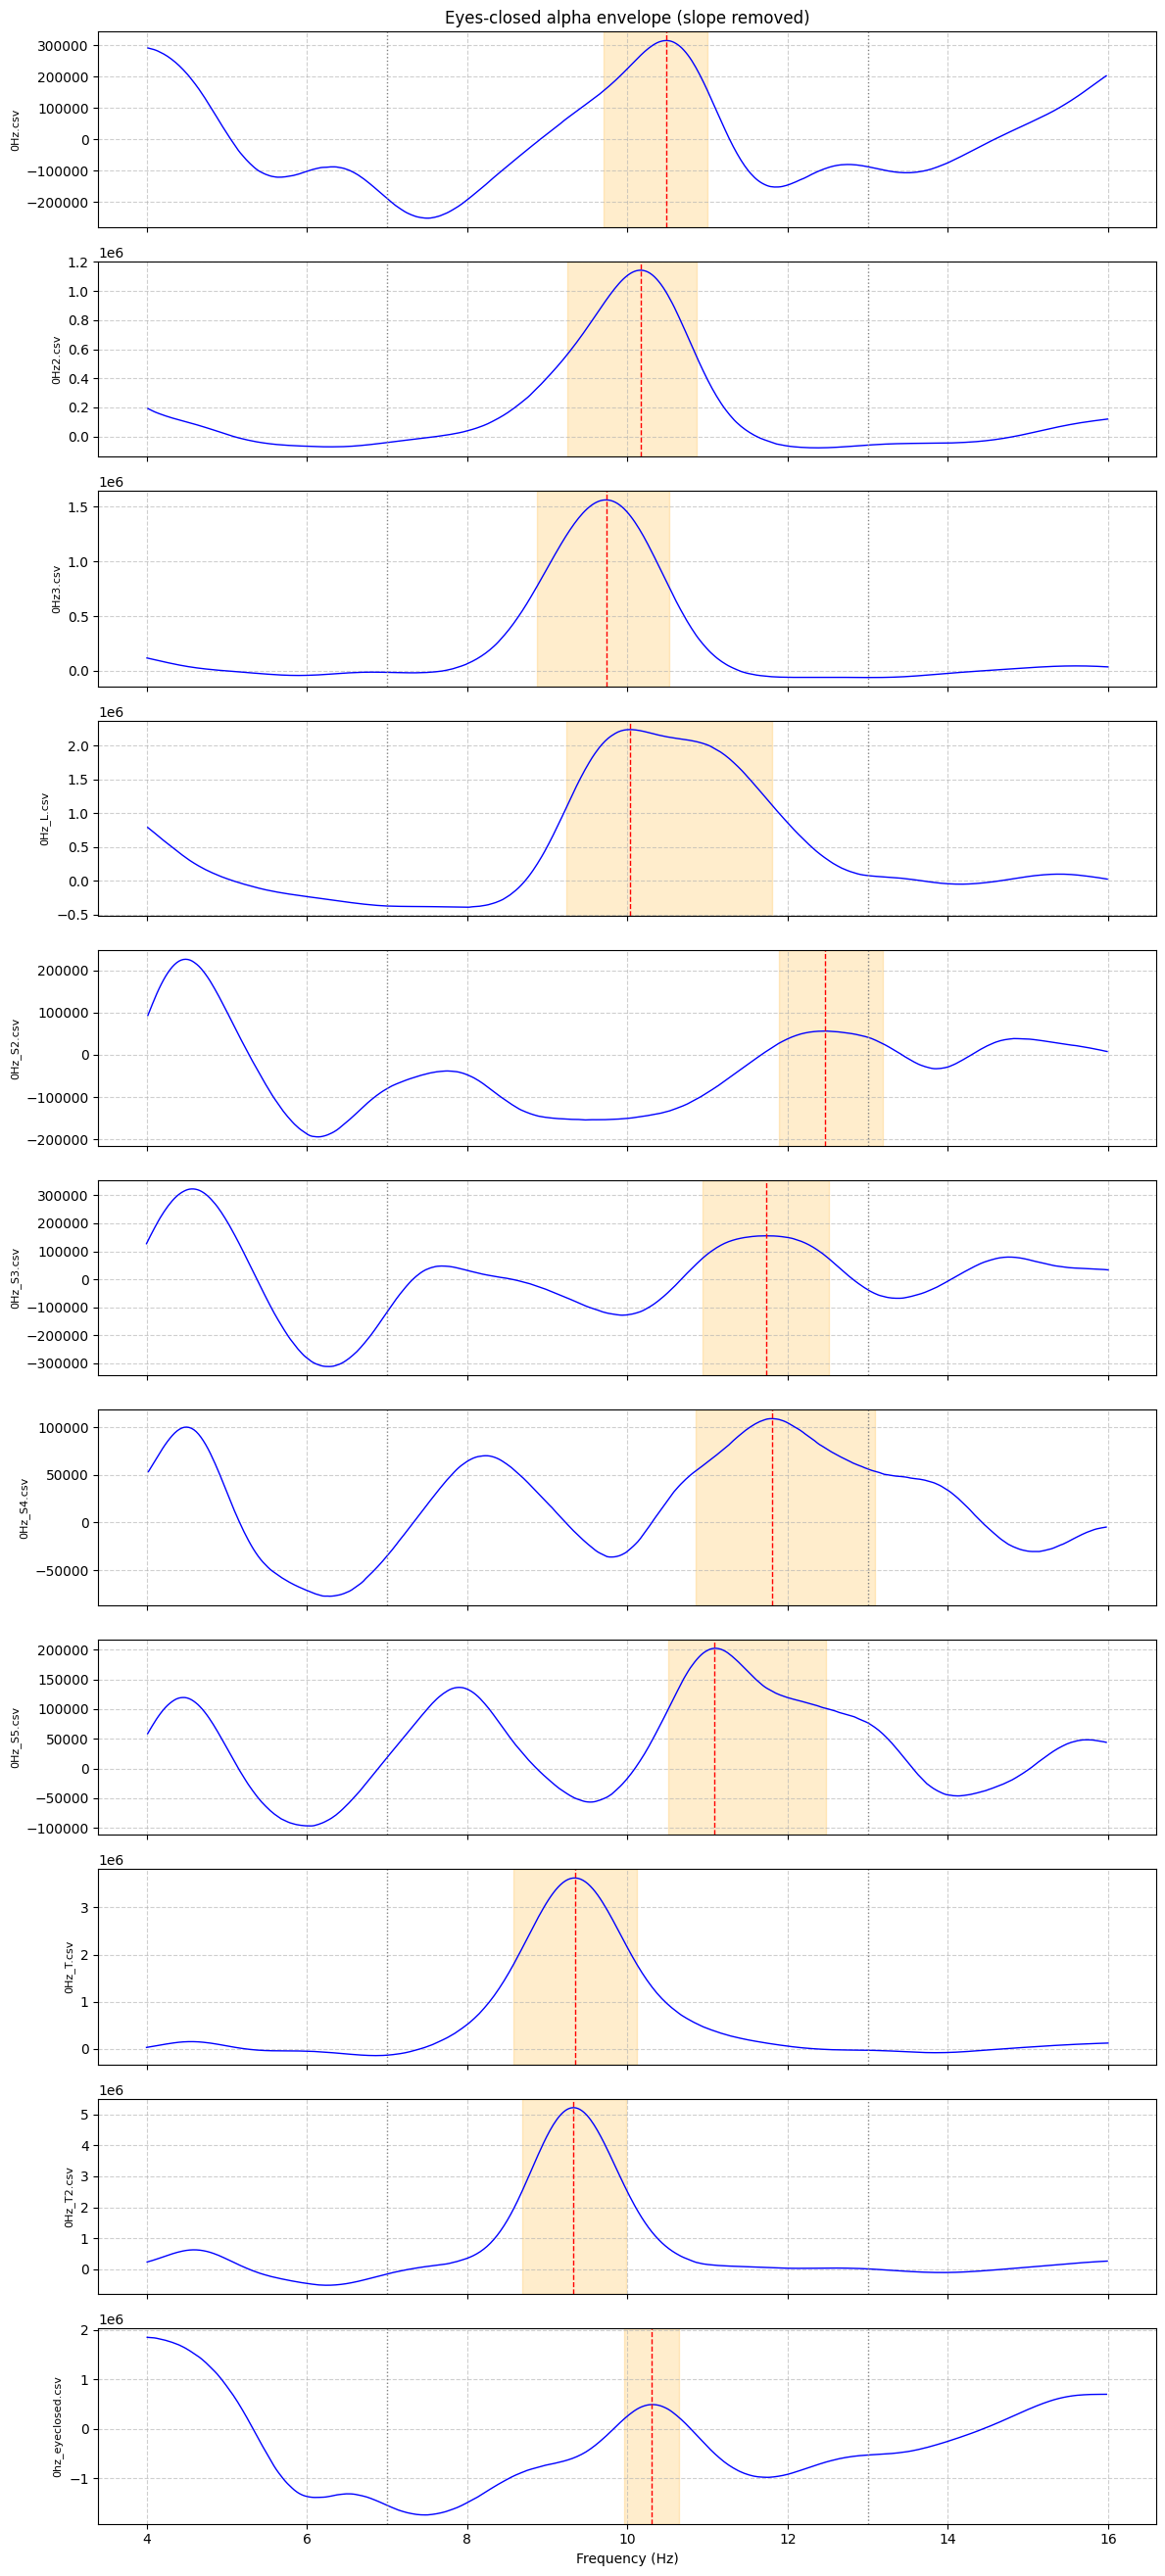

In [53]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Eyes-closed alpha is a hump, not one of the SSVEP lines. Locate the hump on the
# weighted Hann spectrum: subtract the slope fitted on the 4-7 Hz and 13-16 Hz
# shoulders, then take the top and the power-weighted center of what remains in 7-13 Hz.
alpha_weights = np.array([0.15, 0.35, 0.35, 0.15])
rest_paths = sorted(
    f for f in glob.glob('*.csv')
    if os.path.basename(f).lower().startswith('0hz') and 'eyeopen' not in os.path.basename(f).lower()
)

def alpha_envelope(eeg, sampling_rate, weights):
    n = eeg.shape[0]
    taper = np.hanning(n)
    freqs = np.fft.rfftfreq(n, 1.0 / sampling_rate)
    power = np.zeros(len(freqs))
    for ch in range(eeg.shape[1]):
        centered = eeg[:, ch] - np.mean(eeg[:, ch])
        power += weights[ch] * np.abs(np.fft.rfft(centered * taper)) ** 2
    power /= np.sum(weights)

    df = freqs[1] - freqs[0]
    sigma = 0.5 / df
    radius = max(1, int(round(3 * sigma)))
    k = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (k / sigma) ** 2)
    kernel /= kernel.sum()
    smooth = np.convolve(power, kernel, mode='same')

    shoulders = ((freqs >= 4.0) & (freqs < 7.0)) | ((freqs > 13.0) & (freqs <= 16.0))
    slope, intercept = np.polyfit(freqs[shoulders], smooth[shoulders], 1)
    residual = smooth - (slope * freqs + intercept)

    band = np.where((freqs >= 7.0) & (freqs <= 13.0))[0]
    peak_i = band[int(np.argmax(residual[band]))]
    positive = np.clip(residual[band], 0.0, None)
    center = float(np.sum(freqs[band] * positive) / np.sum(positive))

    half = residual[peak_i] * 0.5
    left = peak_i
    while left > 0 and residual[left] >= half:
        left -= 1
    right = peak_i
    while right < len(residual) - 1 and residual[right] >= half:
        right += 1
    return freqs, residual, float(freqs[peak_i]), center, float(freqs[left]), float(freqs[right])

fig, axes = plt.subplots(len(rest_paths), 1, figsize=(12, 2.4 * len(rest_paths)), sharex=True)
if len(rest_paths) == 1:
    axes = [axes]
for ax, path in zip(axes, rest_paths):
    eeg = pd.read_csv(path)[['Channel_1', 'Channel_2', 'Channel_3', 'Channel_4']].values
    freqs, residual, top, center, left, right = alpha_envelope(eeg, sr, alpha_weights)
    show = (freqs >= 4.0) & (freqs <= 16.0)
    ax.plot(freqs[show], residual[show], color='b', linewidth=1)
    ax.axvspan(left, right, color='orange', alpha=0.2)
    ax.axvline(top, color='r', linestyle='--', linewidth=1)
    ax.axvline(7.0, color='0.5', linestyle=':', linewidth=1)
    ax.axvline(13.0, color='0.5', linestyle=':', linewidth=1)
    ax.set_ylabel(os.path.basename(path), fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.6)
    print(
        f'{os.path.basename(path):22s} mountain top {top:5.2f} Hz, '
        f'envelope center {center:5.2f} Hz, half-power {left:5.2f}-{right:5.2f} Hz'
    )
axes[-1].set_xlabel('Frequency (Hz)')
axes[0].set_title('Eyes-closed alpha envelope (slope removed)')
plt.tight_layout()
plt.show()
